# FQ1 · Are the band-masking peaks noise, or object-dependent?
Follow-up to nb136 Q1 (`decres-rescale-aug10-v1`, ep300, eager fp32). Between train and eval the masking peak moved **224 → 124 Hz in gastro** and **625 → 925 Hz in cardboard**. Is that noise, or do objects (or speakers, or position) read different bands?

Data: **cached only** (`runs/_src9_cache/nb136/q1_{train,eval}.npz` = `q1_single.npz` indexed by `subset720.npz`, asserted below; GT masks from `base.npz`). 240 single-object samples per box and set, 60 each of candle / red-cube / soap dispenser / vase. Importance per band = **relative IoU drop** (mean over samples of clean − masked) / mean clean, the nb136 definition. Nothing is recomputed; CPU only.

**FQ1 answer**
- **The box-level peak is only partly stable.** Plastic's 225 Hz peak holds (bootstrap P(peak) .90 train / .78 eval). Gastro's is not: train 225 Hz wins only 53% of resamples (775 Hz 42%), and eval 125 Hz wins only 32%, with 16 of 18 band CIs overlapping its CI. Cardboard is a near-tie on train (625 Hz 59% / 925 Hz 40%) and decisive on eval (925 Hz 98%). So the "moves" are mostly a re-ranking of near-tied bands. ρ(train, eval) of the box profile is .48 / .71 / .49.
- **Objects differ in how much they depend on every band, not in which bands they read.** Total sensitivity differs strongly: the red-cube is the most band-sensitive object in every box and set (Σ drop 1.2–3.6× the mean of the other three) (label-shuffle p ≤ .006). Shape does not: mean pairwise ρ between object profiles sits on the shuffle null (p_ρ .19–.71), and the z-scored shape dispersion is significant only for plastic train (p .017). The same object's profile agrees train vs eval no better than different objects do (ρ .33–.49 vs .34–.47).
- **Speakers do change the shape, but only on train** (p_ρ .002–.016, p_Fz .002–.04); on eval it is noise (p ≥ .5). Near / far from the laser wall barely matters (shape p ≥ .23, except cardboard train p_Fz .010).
- **Physics:** no evidence that bigger objects read lower bands (ρ(area, weighted mean frequency) = +.23 over 24 cells, sign opposite to the hypothesis). The smallest object (red-cube) has the largest per-band sensitivity (ρ(area, level) = −.63). No masses are stored for these four objects.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
ROOT = Path.cwd().parents[1] if Path.cwd().name == "drafts_136" else Path.cwd()
CACHE = ROOT / "runs/_src9_cache/nb136"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
HZ = 100 + (np.arange(18) * 65 + 32) * 900 / 1169                       # band centres (same as nb136)
BX, SETS, OBJ = ["plastic", "gastro", "cardboard"], ["train", "eval"], ["candle", "red-cube", "soap dispenser", "vase"]
CMAP = {b: plt.get_cmap(c) for b, c in zip(BX, ["Blues", "Greens", "Oranges"])}
Q = {s: np.load(CACHE / f"q1_{s}.npz") for s in SETS}                   # = q1_single.npz indexed by subset720.npz (checked below)
Y = np.load(CACHE / "base.npz")["y"]
QS, SU = np.load(CACHE / "q1_single.npz"), np.load(CACHE / "subset720.npz")
assert (QS["mask_b"][SU["eval_q"]] == Q["eval"]["mask_b"]).all() and (QS["tr_mask_b"][SU["train_q"]] == Q["train"]["mask_b"]).all()
D = {}   # per (set, box): mask_b (240,18), clean, obj, spk, row (CoM row; laser wall = bottom of the overhead crop = large row), area
for s in SETS:
    q = Q[s]
    for b in BX:
        k = q["box"] == b
        D[s, b] = dict(m=q["mask_b"][k].astype(np.float64), c=q["clean"][k].astype(np.float64), obj=q["obj"][k], spk=q["spk"][k],
                       row=q["com"][k, 0], area=Y[q["rows"][k]].sum((1, 2)))
del Y
print({(s, b): len(d["c"]) for (s, b), d in D.items()})
print(pd.crosstab(Q["eval"]["box"], Q["eval"]["obj"]).reindex(BX).to_string())

rel = lambda m, c: m.mean(0) / c.mean()                                 # relative IoU drop per band (nb136 definition)
def boot(m, c, n=1000, seed=0):                                        # (n,18) bootstrap of rel over samples
    i = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return m[i].mean(1) / c[i].mean(1)[:, None]
wmf = lambda r: (HZ * np.clip(r, 0, None)).sum(-1) / np.clip(r, 0, None).sum(-1)   # importance-weighted mean frequency
rho = lambda a, b: stats.spearmanr(a, b)[0]

{('train', 'plastic'): 240, ('train', 'gastro'): 240, ('train', 'cardboard'): 240, ('eval', 'plastic'): 240, ('eval', 'gastro'): 240, ('eval', 'cardboard'): 240}
col_0      candle  red-cube  soap dispenser  vase
row_0                                            
plastic        60        60              60    60
gastro         60        60              60    60
cardboard      60        60              60    60


## FQ1.1 · Bootstrap of the box-level profile
1000 resamples of the 240 samples per (set, box). Table: peak band, its 95% CI, the share of resamples it stays the peak, the top-3 peak bands, `n_overlap` (bands whose upper CI reaches the peak's lower CI), and the importance-weighted mean frequency with its CI.

  set       box  peak_hz  peak_rel             ci  p_peak                         top3  n_overlap     wmf     wmf_ci
train   plastic      225     0.038 [0.032, 0.046]   0.895 225:0.90, 375:0.09, 275:0.01          4 463.052 [444, 479]
train    gastro      225     0.043 [0.036, 0.050]   0.527 225:0.53, 775:0.42, 275:0.05          5 508.453 [494, 521]
train cardboard      625     0.061 [0.053, 0.071]   0.591 625:0.59, 925:0.40, 675:0.01          4 576.347 [565, 588]
 eval   plastic      225     0.032 [0.019, 0.047]   0.782 225:0.78, 125:0.13, 275:0.06          8 422.942 [384, 463]
 eval    gastro      125     0.034 [0.024, 0.046]   0.319 125:0.32, 375:0.19, 575:0.19         16 515.631 [483, 546]
 eval cardboard      925     0.069 [0.054, 0.087]   0.976 925:0.98, 675:0.02, 625:0.01          3 639.283 [604, 680]
n_overlap = bands whose upper CI reaches the peak band's lower CI (incl. the peak)
plastic rho(train, eval) = 0.48 CI [0.26 0.64]


gastro rho(train, eval) = 0.71 CI [0.3 0.8]


cardboard rho(train, eval) = 0.49 CI [0.31 0.71]


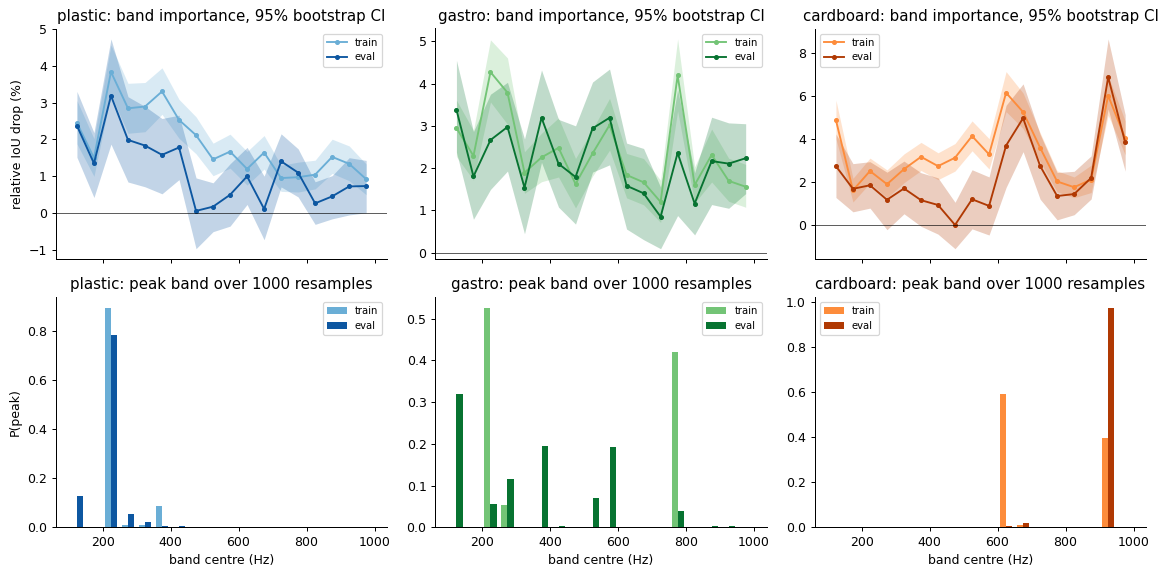

In [2]:
# FQ1.1 · bootstrap the 240 samples per box: 95% CI per band, peak-band distribution
BT, rows = {}, []
for s in SETS:
    for b in BX:
        d = D[s, b]; r = rel(d["m"], d["c"]); bt = BT[s, b] = boot(d["m"], d["c"]); pk = np.bincount(bt.argmax(1), minlength=18) / len(bt)
        lo, hi = np.percentile(bt, [2.5, 97.5], 0); top = np.argsort(-pk)[:3]
        rows.append(dict(set=s, box=b, peak_hz=round(HZ[r.argmax()]), peak_rel=r.max(), ci=f"[{lo[r.argmax()]:.3f}, {hi[r.argmax()]:.3f}]",
                         p_peak=pk[r.argmax()], top3=", ".join(f"{HZ[k]:.0f}:{pk[k]:.2f}" for k in top),
                         n_overlap=int((hi >= lo[r.argmax()]).sum()), wmf=wmf(r), wmf_ci=f"[{np.percentile(wmf(bt), 2.5):.0f}, {np.percentile(wmf(bt), 97.5):.0f}]"))
T1 = pd.DataFrame(rows); print(T1.round(3).to_string(index=False))
print("n_overlap = bands whose upper CI reaches the peak band's lower CI (incl. the peak)")
# train-vs-eval profile agreement per box, with bootstrap CI
for b in BX: print(b, "rho(train, eval) =", round(rho(rel(D["train", b]["m"], D["train", b]["c"]), rel(D["eval", b]["m"], D["eval", b]["c"])), 2),
                   "CI", np.percentile([rho(x, y) for x, y in zip(BT["train", b], BT["eval", b])], [2.5, 97.5]).round(2))

fig, ax = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for j, b in enumerate(BX):
    for i, s in enumerate(SETS):
        d, bt, cm = D[s, b], BT[s, b], CMAP[b]; lo, hi = np.percentile(bt, [2.5, 97.5], 0); col = cm(.5 + .35 * i)
        ax[0, j].fill_between(HZ, lo * 100, hi * 100, color=col, alpha=.25, lw=0); ax[0, j].plot(HZ, rel(d["m"], d["c"]) * 100, "o-", c=col, ms=3, label=s)
        ax[1, j].bar(HZ + (i - .5) * 18, np.bincount(bt.argmax(1), minlength=18) / len(bt), width=18, color=col, label=s)
    ax[0, j].axhline(0, c="k", lw=.5); ax[0, j].set_title(f"{b}: band importance, 95% bootstrap CI"); ax[0, j].legend(fontsize=8)
    ax[1, j].set_title(f"{b}: peak band over 1000 resamples"); ax[1, j].set_xlabel("band centre (Hz)"); ax[1, j].legend(fontsize=8)
ax[0, 0].set_ylabel("relative IoU drop (%)"); ax[1, 0].set_ylabel("P(peak)"); plt.tight_layout(); plt.show()

**Answer.**
- **Plastic: stable.** 225 Hz is the peak in 90% (train) and 78% (eval) of resamples.
- **Gastro: not stable.** Train 225 Hz wins 53% vs 775 Hz 42%. Eval 125 Hz wins only 32% (375 and 575 Hz 19% each), and 16 of 18 band CIs overlap its CI [.024, .046]. "224 → 124 Hz" is a noise-level re-ranking, not a shift.
- **Cardboard: a two-band tie that resolves.** Train 625 Hz 59% / 925 Hz 40%; eval 925 Hz 98%. Both bands are high either way.
- **What is stable is the weighted mean frequency:** 463 / 508 / 576 Hz train, 423 / 516 / 639 Hz eval (CIs ±15–40 Hz). Plastic is lowest and cardboard highest in both sets; cardboard's eval rise (CI [604, 680] vs [565, 588]) is the only real shift.

## FQ1.2 · Per object
Profiles per object (60 samples each) with bootstrap CIs. Tests, label shuffle within box (1000 perms; `_spk` = shuffled within speaker, 300 perms):
- **ρ** = mean pairwise Spearman between the 4 object profiles (shape similarity; p_ρ = P(null ≤ obs)).
- **F** = Σ n·‖rel_obj − rel_box‖² (level + shape). **Fz** = the same on per-object z-scored profiles (shape only).
- `lvl` = Σ over bands of the relative drop (%), i.e. the object's overall sensitivity.
- Train ↔ eval ρ of the same object vs different objects, and the within-object split-half ρ (30 vs 30), the noise ceiling at n = 60.

  set       box   rho  rho_null  p_rho     F  F_null   p_F       Fz  Fz_null  p_Fz  p_F_spk  p_Fz_spk
train   plastic 0.726     0.748  0.306 0.284   0.090 0.001  993.444  700.642 0.017    0.003     0.017
train    gastro 0.637     0.668  0.295 0.305   0.123 0.001  930.428  845.631 0.273    0.003     0.282
train cardboard 0.839     0.831  0.591 0.868   0.165 0.001  481.525  490.028 0.509    0.003     0.578
 eval   plastic 0.409     0.432  0.398 0.723   0.275 0.001 1958.374 1786.742 0.246    0.003     0.342
 eval    gastro 0.158     0.225  0.194 0.710   0.399 0.003 2847.914 2563.577 0.113    0.027     0.266
 eval cardboard 0.499     0.463  0.705 1.037   0.628 0.006 1244.420 1274.300 0.565    0.023     0.571
  set       box  lvl candl  lvl red-c  lvl soap   lvl vase peak candle peak red-cube peak soap dispenser peak vase
train   plastic       25.1       52.2       30.4      28.9         225           325                 375       225
train    gastro       32.0       53.3       52.1      34


within-object split-half ρ (30 vs 30) = noise ceiling for between-object ρ at n=60
   set       box  split_half_rho
train   plastic            0.65
train    gastro            0.55
train cardboard            0.76
 eval   plastic            0.23
 eval    gastro            0.14
 eval cardboard            0.34


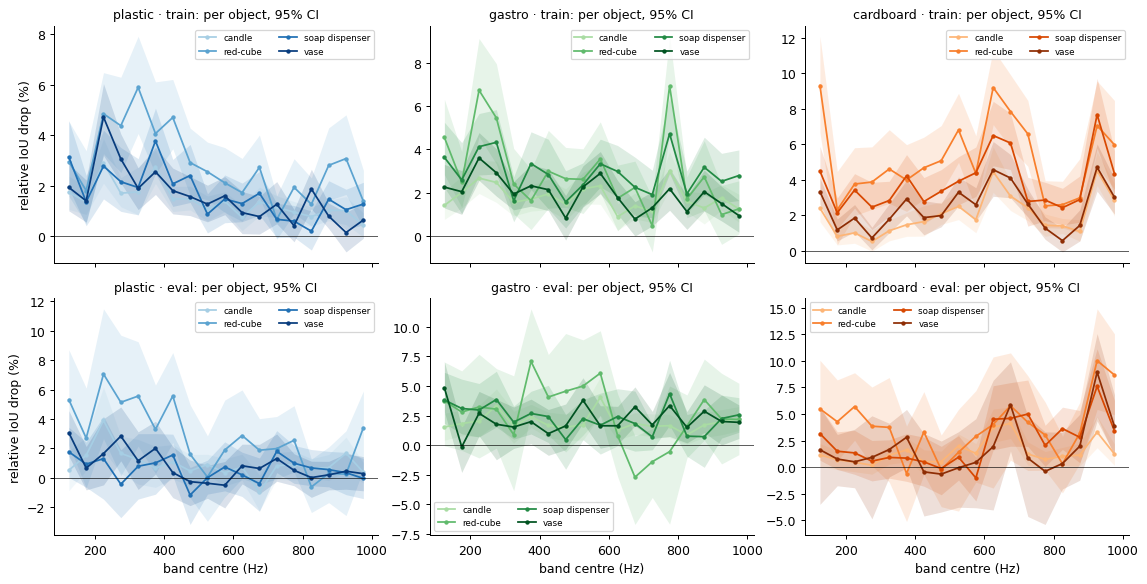

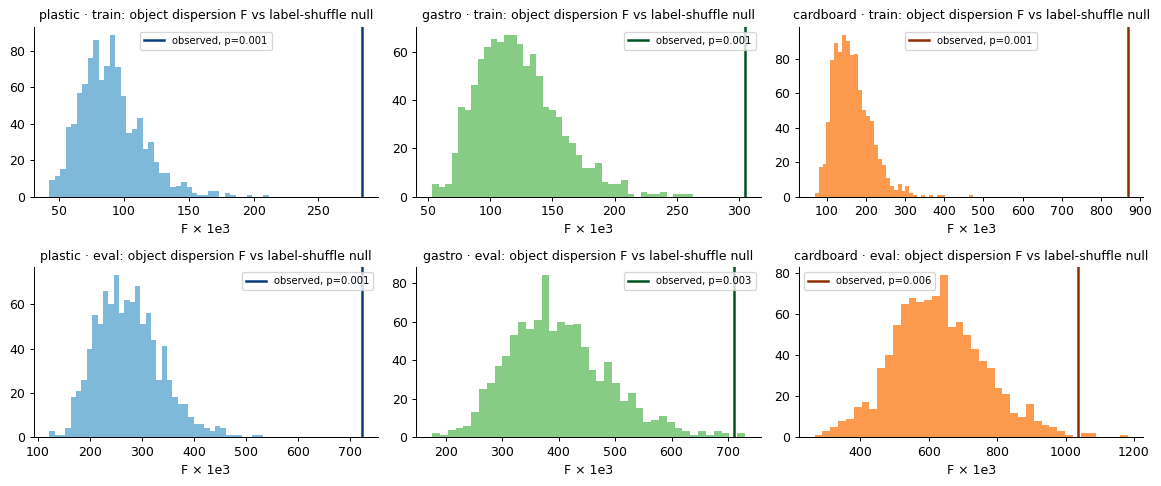

In [3]:
# FQ1.2 · grouping test, reused for object / speaker / position region
# stat 1 = mean pairwise Spearman ρ between group profiles (low = groups read different bands)
# stat 2 = dispersion F = Σ_g n_g ||rel_g − rel_box||² (large = groups differ, level or shape)
# stat 3 = shape-only Fz: the same on per-group z-scored profiles (removes each group's overall level)
# null: shuffle labels within the box (and, stricter, within speaker for objects)
def profiles(d, g, G): return np.array([rel(d["m"][g == k], d["c"][g == k]) for k in G])
z = lambda P: (P - P.mean(-1, keepdims=True)) / P.std(-1, keepdims=True)
def stats_(P, R0, n): Z = z(P); return (np.mean([rho(P[i], P[j]) for i in range(len(P)) for j in range(i + 1, len(P))]),
                                        (n[:, None] * (P - R0) ** 2).sum(), (n[:, None] * (Z - (n[:, None] * Z).sum(0) / n.sum()) ** 2).sum())
def gtest(d, g, G, strata=None, n_perm=1000, seed=0):
    rng, n, R0 = np.random.default_rng(seed), np.array([(g == k).sum() for k in G]), rel(d["m"], d["c"])
    obs, null = stats_(profiles(d, g, G), R0, n), []
    for _ in range(n_perm):
        gp = g.copy()
        for st in (np.unique(strata) if strata is not None else [None]):
            k = np.arange(len(g)) if st is None else np.nonzero(strata == st)[0]; gp[k] = rng.permutation(g[k])
        null.append(stats_(profiles(d, gp, G), R0, n))
    null = np.array(null)
    return dict(rho=obs[0], rho_null=null[:, 0].mean(), p_rho=(1 + (null[:, 0] <= obs[0]).sum()) / (1 + n_perm),
                F=obs[1], F_null=null[:, 1].mean(), p_F=(1 + (null[:, 1] >= obs[1]).sum()) / (1 + n_perm),
                Fz=obs[2], Fz_null=null[:, 2].mean(), p_Fz=(1 + (null[:, 2] >= obs[2]).sum()) / (1 + n_perm)), null
def gboot(d, g, G, seed=0): return {k: boot(d["m"][g == k], d["c"][g == k], seed=seed) for k in G}

OB, NULL, rows = {}, {}, []
for s in SETS:
    for b in BX:
        d = D[s, b]; OB[s, b] = gboot(d, d["obj"], OBJ)
        r, NULL[s, b] = gtest(d, d["obj"], OBJ); r2, _ = gtest(d, d["obj"], OBJ, strata=d["spk"], n_perm=300)
        rows.append(dict(set=s, box=b, **{k: round(v, 3) for k, v in r.items()}, p_F_spk=round(r2["p_F"], 3), p_Fz_spk=round(r2["p_Fz"], 3),
                         **{f"lvl {o[:5]}": round(100 * rel(d['m'][d['obj'] == o], d['c'][d['obj'] == o]).sum(), 1) for o in OBJ},
                         **{f"peak {o}": f"{HZ[rel(d['m'][d['obj'] == o], d['c'][d['obj'] == o]).argmax()]:.0f}" for o in OBJ}))
T2 = pd.DataFrame(rows); print(T2.drop(columns=[c for c in T2 if c.startswith(("peak", "lvl"))]).to_string(index=False))
print(T2[["set", "box"] + [c for c in T2 if c.startswith(("peak", "lvl"))]].to_string(index=False), "\n(lvl = Σ_bands relative drop, %)")
# same object train vs eval, vs different objects
rows = []
for b in BX:
    P = {s: profiles(D[s, b], D[s, b]["obj"], OBJ) for s in SETS}
    C = np.array([[rho(P["train"][i], P["eval"][j]) for j in range(4)] for i in range(4)])
    rows.append(dict(box=b, **{o: round(C[i, i], 2) for i, o in enumerate(OBJ)}, same=round(np.diag(C).mean(), 2), different=round(C[~np.eye(4, dtype=bool)].mean(), 2),
                     box_level=round(rho(rel(D["train", b]["m"], D["train", b]["c"]), rel(D["eval", b]["m"], D["eval", b]["c"])), 2)))
T3 = pd.DataFrame(rows); print("\nρ(train profile, eval profile)\n", T3.to_string(index=False))
# split-half noise ceiling per object: ρ between two random halves of 30 (mean of 200 splits)
rng = np.random.default_rng(1); rows = []
for s in SETS:
    for b in BX:
        d = D[s, b]; v = []
        for o in OBJ:
            k = np.nonzero(d["obj"] == o)[0]
            for _ in range(200): p = rng.permutation(k); v.append(rho(rel(d["m"][p[:30]], d["c"][p[:30]]), rel(d["m"][p[30:]], d["c"][p[30:]])))
        rows.append(dict(set=s, box=b, split_half_rho=round(np.mean(v), 2)))
print("\nwithin-object split-half ρ (30 vs 30) = noise ceiling for between-object ρ at n=60\n", pd.DataFrame(rows).to_string(index=False))

def lines(G_by, labels, title, fig_rows=SETS):
    fig, ax = plt.subplots(len(fig_rows), 3, figsize=(13, 3.3 * len(fig_rows)), sharex=True, squeeze=False)
    for i, s in enumerate(fig_rows):
        for j, b in enumerate(BX):
            a, G = ax[i, j], G_by[s, b]
            for k, (g, bt) in enumerate(G.items()):
                col = CMAP[b](.35 + .6 * k / max(1, len(G) - 1)); lo, hi = np.percentile(bt, [2.5, 97.5], 0)
                a.fill_between(HZ, lo * 100, hi * 100, color=col, alpha=.15, lw=0); a.plot(HZ, np.median(bt, 0) * 100, "o-", c=col, ms=2.5, lw=1.4, label=labels(g))
            a.axhline(0, c="k", lw=.5); a.set_title(f"{b} · {s}: {title}", fontsize=10); a.legend(fontsize=7, ncol=2)
        ax[i, 0].set_ylabel("relative IoU drop (%)")
    [a.set_xlabel("band centre (Hz)") for a in ax[-1]]; plt.tight_layout(); plt.show()
lines(OB, str, "per object, 95% CI")

fig, ax = plt.subplots(2, 3, figsize=(13, 5.5))
for i, s in enumerate(SETS):
    for j, b in enumerate(BX):
        a, nl, r = ax[i, j], NULL[s, b][:, 1], T2[(T2.set == s) & (T2.box == b)].iloc[0]
        a.hist(nl * 1e3, 40, color=CMAP[b](.45)); a.axvline(r.F * 1e3, c=CMAP[b](.95), lw=2, label=f"observed, p={r.p_F:.3f}")
        a.set_title(f"{b} · {s}: object dispersion F vs label-shuffle null", fontsize=10); a.legend(fontsize=8); a.set_xlabel("F × 1e3")
plt.tight_layout(); plt.show()

**Answer.**
- **Shape: object ≈ noise.** Between-object ρ equals the shuffle null in every cell (train .73 / .64 / .84 vs null .75 / .67 / .83; eval .41 / .16 / .50 vs .43 / .23 / .46; p_ρ .19–.71). It also matches the within-object split-half ceiling (train .65 / .55 / .76, eval .23 / .14 / .34): two random halves of one object disagree as much as two objects do. Shape-only Fz is significant only in plastic train (p .017; .27–.57 elsewhere).
- **No object signature that carries over.** ρ(train, eval) for the same object is .33 / .42 / .49 (plastic / gastro / cardboard) vs .37 / .34 / .47 for different objects. Per-object peaks scatter (e.g. gastro eval 575 / 375 / 775 / 125 Hz).
- **Level: a real object effect.** F is 2–3× its null (p ≤ .006, also within speaker p ≤ .027). It comes from overall sensitivity: the red-cube's Σ drop is 52 / 53 / 94% train and 51 / 47 / 69% eval, vs 10–70% for the others (1.2–3.6× their mean). Dropping one band hurts the small cube more, but across the same bands.

## FQ1.3 · Speaker and position region (secondary)
Same tests. Speakers with < 15 samples in a box (speaker 4: 2–9 eval samples) are dropped. Region = GT-mask CoM row above / below the box median (the laser wall is the bottom of the overhead crop, nb96 §9), so near and far have 120 samples each.

speaker counts
     train                     eval                 
  plastic gastro cardboard plastic gastro cardboard
1      56     78        51      51     69        65
3      72     85        55      57     77        56
4       0      0         0       8      9         2
5      60      0        64      61      0        60
7      52     77        70      63     85        57
CoM row range per box (64 px): {('train', 'plastic'): (np.float64(12.2), np.float64(29.5), np.float64(47.9)), ('train', 'gastro'): (np.float64(10.6), np.float64(32.6), np.float64(51.0)), ('train', 'cardboard'): (np.float64(8.4), np.float64(27.3), np.float64(50.6)), ('eval', 'plastic'): (np.float64(12.9), np.float64(30.2), np.float64(48.1)), ('eval', 'gastro'): (np.float64(10.5), np.float64(32.0), np.float64(51.3)), ('eval', 'cardboard'): (np.float64(8.5), np.float64(30.0), np.float64(50.7))}


  group   set       box  n_groups   rho  rho_null  p_rho     F  F_null   p_F       Fz  Fz_null  p_Fz
speaker train   plastic         4 0.475     0.750  0.002 0.185   0.089 0.004 1591.532  693.356 0.002
 region train   plastic         2 0.889     0.851  0.772 0.030   0.030 0.411  318.275  255.898 0.230
speaker train    gastro         3 0.583     0.725  0.016 0.139   0.083 0.054  864.345  603.335 0.040
 region train    gastro         2 0.814     0.793  0.591 0.032   0.042 0.675  343.427  317.554 0.369
speaker train cardboard         4 0.723     0.829  0.002 0.414   0.167 0.004  944.647  488.021 0.002
 region train cardboard         2 0.853     0.913  0.074 0.137   0.057 0.028  365.366  180.632 0.010
speaker  eval   plastic         4 0.431     0.361  0.792 0.193   0.259 0.852 1817.728 1941.669 0.687
 region  eval   plastic         2 0.589     0.647  0.279 0.137   0.091 0.114  888.937  799.792 0.347
speaker  eval    gastro         3 0.337     0.335  0.509 0.208   0.233 0.629 1746.191 1883.

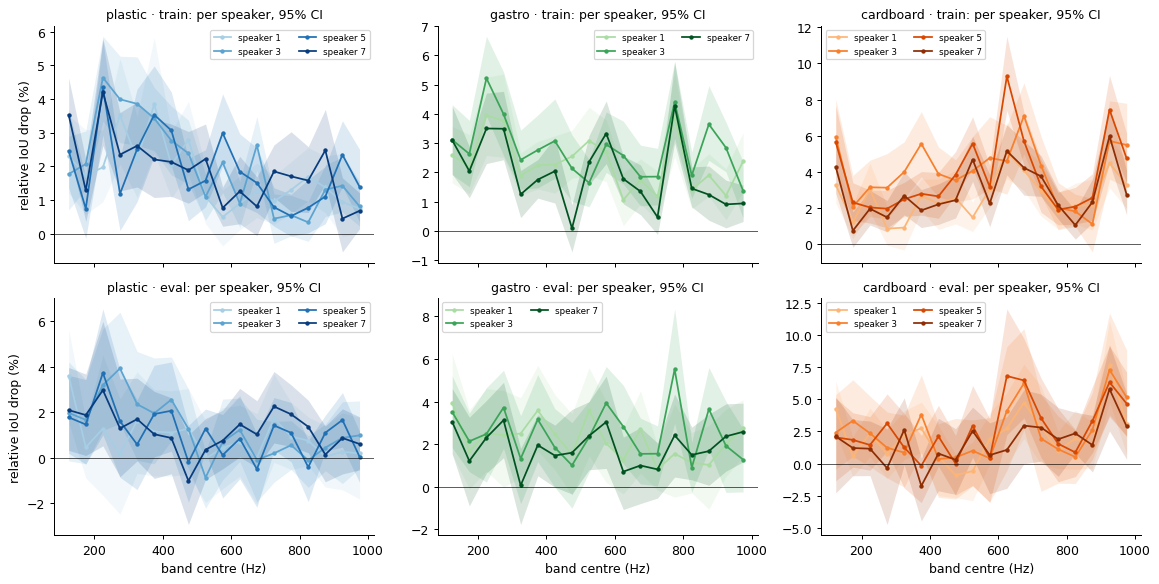

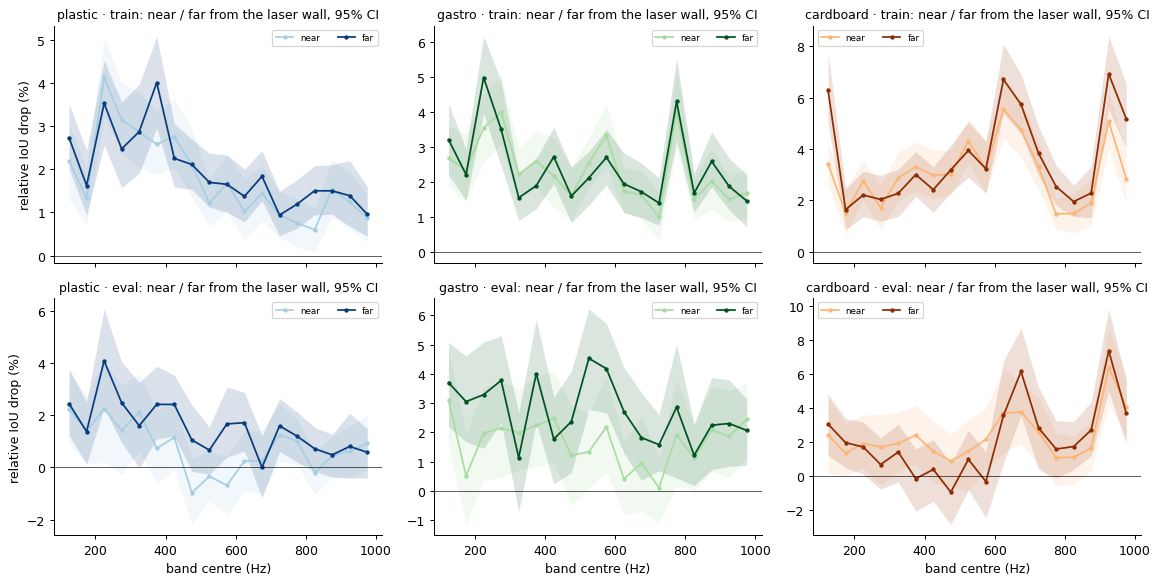

In [4]:
# FQ1.3 · same grouping for speaker and for position region
# region: CoM row of the GT mask; the laser wall is the bottom of the overhead crop (nb96 §9), so near = row above the box's median (per set)
for s in SETS:
    for b in BX: d = D[s, b]; d["reg"] = np.where(d["row"] > np.median(d["row"]), "near", "far")
print("speaker counts\n", pd.DataFrame({(s, b): pd.Series(D[s, b]["spk"]).value_counts() for s in SETS for b in BX}).fillna(0).astype(int).to_string())
print("CoM row range per box (64 px):", {(s, b): (D[s, b]["row"].min().round(1), np.median(D[s, b]["row"]).round(1), D[s, b]["row"].max().round(1)) for s in SETS for b in BX})
SP, RG, rows = {}, {}, []
for s in SETS:
    for b in BX:
        d = D[s, b]; G = [k for k in np.unique(d["spk"]) if (d["spk"] == k).sum() >= 15]; k = np.isin(d["spk"], G); dk = {x: v[k] for x, v in d.items()}
        SP[s, b], RG[s, b] = gboot(dk, dk["spk"], G), gboot(d, d["reg"], ["near", "far"])
        for name, dd, g, GG in (("speaker", dk, dk["spk"], G), ("region", d, d["reg"], ["near", "far"])):
            r, _ = gtest(dd, g, GG, n_perm=500)
            P = profiles(dd, g, GG)
            rows.append(dict(group=name, set=s, box=b, n_groups=len(GG), **{x: round(v, 3) for x, v in r.items()},
                             peaks=" / ".join(f"{gg}:{HZ[p.argmax()]:.0f}" for gg, p in zip(GG, P)), wmf=" / ".join(f"{gg}:{wmf(p):.0f}" for gg, p in zip(GG, P)),
                             lvl=" / ".join(f"{gg}:{100 * p.sum():.0f}" for gg, p in zip(GG, P))))
T4 = pd.DataFrame(rows); print(T4.drop(columns=["peaks", "wmf", "lvl"]).to_string(index=False)); print(T4[["group", "set", "box", "peaks", "wmf", "lvl"]].to_string(index=False))
lines(SP, lambda g: f"speaker {g}", "per speaker, 95% CI")
lines(RG, str, "near / far from the laser wall, 95% CI")

**Answer.**
- **Speaker changes the shape on train** (p_ρ .002 / .016 / .002, p_Fz .002 / .040 / .002), e.g. plastic speaker 1 peaks at 375 Hz while the other speakers peak at 225 Hz, and cardboard speaker 7 peaks at 925 Hz vs 625–675 Hz. **On eval it is noise** (p_ρ .51–.82, p_Fz .56–.71). The memorised train regime reads speaker-specific bands; this does not hold on held-out positions.
- **Region: weak.** Shape p_Fz ≥ .23 except cardboard train (.010). Level differs only in gastro eval (near 30% vs far 48%, p_F .042) and cardboard train (p .028). Weighted mean frequency near / far differs by ≤ 46 Hz.

## FQ1.4 · Physics check: do bigger objects read lower bands?
No masses are stored for candle / red-cube / soap dispenser / vase (only the cylinder series has grams), so size = median GT mask area. Per (set, box, object): importance-weighted mean frequency with bootstrap CI, and overall level.

  set       box            obj  area  clean    wmf  wmf_lo  wmf_hi   lvl
train   plastic         candle 132.5   0.93 467.06  440.80  491.75 25.13
train   plastic       red-cube  36.0   0.93 481.59  446.65  512.10 52.20
train   plastic soap dispenser  62.5   0.93 455.17  421.08  486.99 30.39
train   plastic           vase  77.0   0.92 434.03  396.43  468.03 28.90
train    gastro         candle 113.0   0.92 526.60  505.39  545.76 32.03
train    gastro       red-cube  32.0   0.89 482.21  451.29  512.61 53.34
train    gastro soap dispenser  50.0   0.92 533.52  507.94  560.86 52.12
train    gastro           vase  67.0   0.91 493.35  465.60  517.99 34.94
train cardboard         candle 148.5   0.92 616.17  591.65  642.71 36.66
train cardboard       red-cube  40.0   0.89 553.75  527.97  577.55 93.98
train cardboard soap dispenser  74.0   0.91 582.27  566.89  597.96 69.60
train cardboard           vase  86.0   0.91 580.68  556.44  605.21 43.74
 eval   plastic         candle 135.5   0.81 463.20 

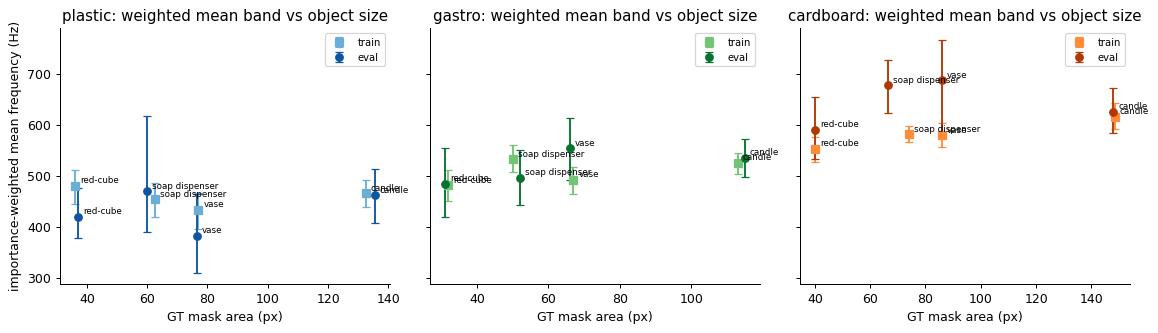

In [5]:
# FQ1.4 · physics check: weighted mean frequency (and total level) per object vs object size
# no masses are stored for these four objects; size = GT mask area (px of 64×64), median over the object's samples in that box (one eval gastro red-cube mask, pos 1255, is the full frame: 4069 px, IoU .02)
rows = []
for s in SETS:
    for b in BX:
        d = D[s, b]
        for o in OBJ:
            k, bt = d["obj"] == o, OB[s, b][o]; w = wmf(bt)
            rows.append(dict(set=s, box=b, obj=o, area=np.median(d["area"][k]), clean=d["c"][k].mean(), wmf=wmf(rel(d["m"][k], d["c"][k])),
                             wmf_lo=np.percentile(w, 2.5), wmf_hi=np.percentile(w, 97.5), lvl=100 * rel(d["m"][k], d["c"][k]).sum()))
T5 = pd.DataFrame(rows); print(T5.round(2).to_string(index=False))
print("\nSpearman over the 24 (set, box, object) cells:", {c: round(rho(T5.area, T5[c]), 2) for c in ("wmf", "lvl", "clean")})
print("within box (4 objects × 2 sets = 8 points):", {b: {c: round(rho(T5.area[T5.box == b], T5[c][T5.box == b]), 2) for c in ("wmf", "lvl")} for b in BX})
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, b in zip(ax, BX):
    for i, s in enumerate(SETS):
        t = T5[(T5.box == b) & (T5.set == s)]; col = CMAP[b](.5 + .35 * i)
        a.errorbar(t.area, t.wmf, yerr=[t.wmf - t.wmf_lo, t.wmf_hi - t.wmf], fmt="o" if i else "s", c=col, capsize=3, label=s)
        [a.annotate(o, (x, y), fontsize=7, xytext=(4, 2), textcoords="offset points") for o, x, y in zip(t.obj, t.area, t.wmf)]
    a.set_title(f"{b}: weighted mean band vs object size"); a.set_xlabel("GT mask area (px)"); a.legend(fontsize=8)
ax[0].set_ylabel("importance-weighted mean frequency (Hz)"); plt.tight_layout(); plt.show()

**Answer.** **No.** Over the 24 (set, box, object) cells, ρ(area, weighted mean frequency) = **+.23**, the opposite sign to "larger → lower bands"; within box it is −.19 / +.60 / +.37 on 8 points each, and the per-object CIs (±20–115 Hz) overlap. Box stiffness matters much more than the object (plastic ≈ 380–480 Hz < gastro ≈ 480–555 < cardboard ≈ 555–690). The one robust object fact is **size vs level**: ρ(area, Σ drop) = **−.63** (−.50 / −.90 / −.76 within box). The red-cube (≈ 31–41 px) is the most band-sensitive object everywhere, which fits a small mask whose IoU is fragile to any lost evidence rather than a mass-loading frequency shift.